# Analyse sémantique

Dans ce notebook, nous allons explorer différentes méthodes de NLP pour choisir celle qui donne les meilleurs résultats :
- Bag of Words : 1 mot = 1 occurence
- TF-IDF : même principe, mais pondère les mots en fonction de leur rareté dans le corpus.
- N-2 : décompte les combinaisons de 2 mots (ex : très bien)
- ANNFIN : Donne un score émotionnel aux mots
- LDA : trouve les catégories.

https://regenerativetoday.com/countvectorizer-to-extract-features-from-texts-in-python-in-details/
https://towardsdatascience.com/basics-of-countvectorizer-e26677900f9c/
https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html
https://www.projectpro.io/recipes/use-count-vectorizer
https://stackoverflow.com/questions/44083683/countvectorizer-with-pandas-dataframe


In [1]:
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
df = pd.read_csv('df_preprocessed.csv')
df

,avis,dates,series,notes,plateforme,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght,tokens,tokens_lemmatized
0,Honest Opinion - Turns out Westeros is way mor...,2026-01-24,A Knight of the Seven Kingdoms,8.0,Imdb,1,0,0,0,0,0,419,honest opinion turns westeros way interesting ...,honest opinion turn westeros way interesting e...
1,"So Far, So Good (Don't Screw It Up) - The firs...",2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,1,0,0,0,0,638,far good screw first episode knight seven king...,far good screw first episode knight seven king...
2,A proper return to Westeros - I stayed up for ...,2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,1,0,0,0,0,1334,proper return westeros stayed 3 uk premiere on...,proper return westeros stayed 3 uk premiere on...
3,The only disappointment i had with ep 1 - Its ...,2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,0,1,0,1,0,404,disappointment ep 1 42 minuts expected hour ho...,disappointment ep 1 42 minuts expected hour ho...
4,Really freaking good with only one bad moment ...,2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,1,0,0,0,0,1964,really freaking good one bad moment far knight...,really freaking good one bad moment far knight...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1407,Mediocre filmmaking - Weak script in combinati...,2025-10-29,King & Conqueror,1.0,Imdb,-1,0,1,0,1,0,349,mediocre filmmaking weak script combination we...,mediocre filmmaking weak script combination we...
1408,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,3.0,Imdb,-1,0,0,0,2,0,526,drunk history many reviewers noted events noth...,drunk history many reviewer noted event nothin...
1409,I get it... -,2026-02-26,King & Conqueror,7.0,Imdb,1,0,0,0,0,0,14,get,get
1410,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,3.0,Imdb,-1,2,0,0,0,0,322,realism earl military crews count 5 8 soldiers...,realism earl military crew count 5 8 soldier s...


In [ ]:
# Identification des valeurs nulles
print(df.isna().sum())
df[df['tokens_lemmatized'].isna()]

avis                              0
dates                             0
series                            0
notes                             0
plateforme                        0
notes_3                           0
nb_capital_words                  0
nb_exclamation_points             0
nb_exclamation_points_chains      0
nb_interrogation_points           0
nb_interrogation_points_chains    0
lenght                            0
tokens                            2
tokens_lemmatized                 2
dtype: int64


,avis,dates,series,notes,plateforme,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght,tokens,tokens_lemmatized
329,👌 -,2026-02-07,A Knight of the Seven Kingdoms,10.0,Imdb,1,0,0,0,0,0,4,NaN,NaN
766,"No, no, no, -",2026-02-23,A Knight of the Seven Kingdoms,8.0,Imdb,1,0,0,0,0,0,14,NaN,NaN


In [13]:
# Suppression valeurs nulles et réinitialisation de l'index
df = df.dropna()
df = df.reset_index()

In [31]:
# Vectoriser en conservant les 100 mots les plus cités
vectorizer = CountVectorizer(max_features=100,
                             stop_words=['say', 'one'])

count_matrix = vectorizer.fit_transform(df['tokens_lemmatized'])
print(count_matrix.shape)
print(vectorizer.vocabulary_)

(1410, 100)
{'westeros': np.int64(94), 'way': np.int64(92), 'every': np.int64(27), 'minute': np.int64(56), 'dragon': np.int64(16), 'throne': np.int64(84), 'drama': np.int64(17), 'well': np.int64(93), 'heart': np.int64(40), 'epic': np.int64(23), 'like': np.int64(50), 'honor': np.int64(42), 'far': np.int64(30), 'good': np.int64(36), 'first': np.int64(32), 'episode': np.int64(24), 'knight': np.int64(48), 'seven': np.int64(73), 'kingdom': np.int64(47), 'start': np.int64(78), 'feel': np.int64(31), 'series': np.int64(71), 'martin': np.int64(55), 'work': np.int64(96), 'storytelling': np.int64(81), 'made': np.int64(52), 'house': np.int64(44), 'never': np.int64(60), 'season': np.int64(68), 'game': np.int64(33), 'book': np.int64(10), 'got': np.int64(37), 'ser': np.int64(70), 'dunk': np.int64(19), 'would': np.int64(98), 'give': np.int64(35), 'know': np.int64(49), 'story': np.int64(80), 'much': np.int64(58), 'make': np.int64(53), 'plot': np.int64(64), 'time': np.int64(85), 'fan': np.int64(29), 'ch

In [32]:
count_array = count_matrix.toarray()

count_df = pd.DataFrame(data=count_array, columns=vectorizer.get_feature_names_out())
count_df

,10,acting,action,actor,also,amazing,back,battle,best,better,...,watch,watching,way,well,westeros,without,work,world,would,writing
0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,1,1,2,1,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1405,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1406,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1407,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1408,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


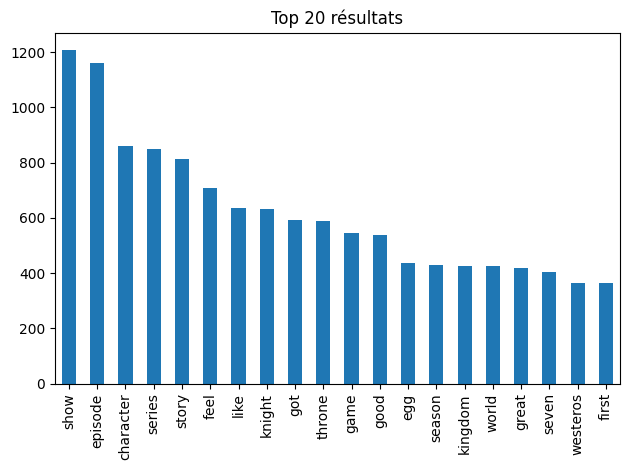

In [35]:
import matplotlib.pyplot as plt

top_n = 20
count_df.sum(axis=0).sort_values(ascending=False).head(top_n).plot(kind='bar')
plt.title(f"Top {top_n} résultats")
plt.tight_layout()
plt.show()

Cette méthode est intéressante mais nous laisse sur notre fin. Effectivements, 'show' et 'épisode' sont compréhensibles avec les mots qui suivent, alors que character ou story peuvent d'interpréter.

Nous essayerons donc la méthode des N-words.